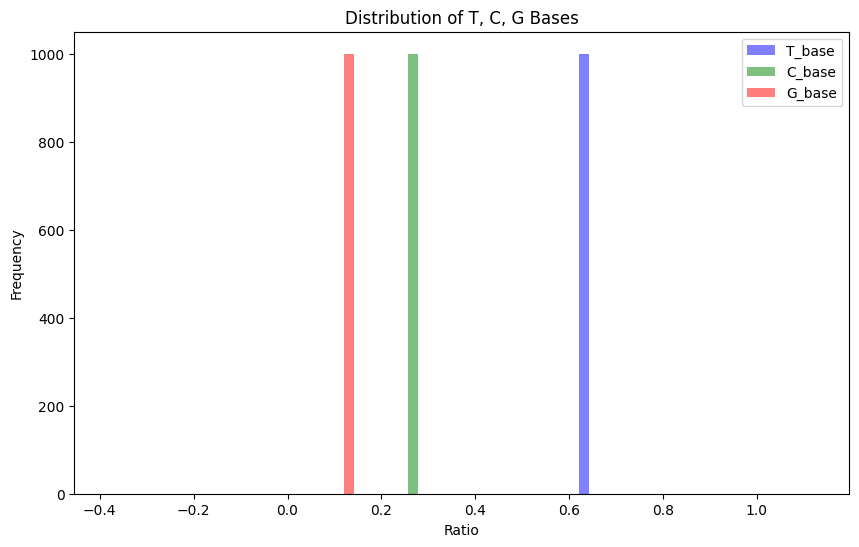

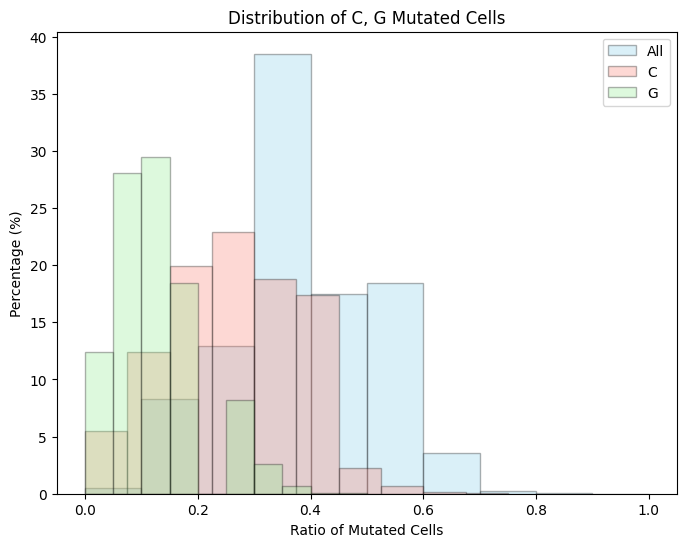

In [15]:
# import
from src.py_utils import *
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages

random.seed(2)

resampleNum = 1000
refBase = "T"
#baseQualityInfoOnesite = "||30|||;||30|||;||30|||;|22||||;|41||||;|41||||;|41||||;||37|||;|37||||;|41||||;|41||||;|||30||"
baseQualityInfoOnesite = "||30|||;||30|||;|22||||;|41||||;|41||||;|41||||;|37||||;|||30||"

readcountsNum, baseWeight, tmpDic, tmpDicP, readcountsWeight = shuffle_reads_features(refBase,baseQualityInfoOnesite)

samples_random_baseQuaInfo = []
for i in range(0, resampleNum):
    sample_random_baseQuaInfo_tmp = shuffle_reads_baseonFeatures(readcountsNum, baseWeight, tmpDic, tmpDicP, readcountsWeight)
    samples_random_baseQuaInfo.append(sample_random_baseQuaInfo_tmp)

def get_cellMut_type(cellbaseQualityInfo, refBase):
    # |22|30|||
    cellInfoSets = cellbaseQualityInfo.split("|")
    baseRes = [BASIC_BASE[cellInfoSets.index(i)] for i in cellInfoSets if i != ""]
    baseRes = [base for base in baseRes if base != refBase]
    return baseRes

def count_oneSite_mutType(baseQualityInfoOnesiteList, refBase):
    res_MutType = {"A": 0, "T": 0, "C": 0, "G": 0, "D": 0, "I": 0}
    for baseQualityInfoOnesite in baseQualityInfoOnesiteList:
        onecellMutType = get_cellMut_type(baseQualityInfoOnesite, refBase)
        if onecellMutType == []:
            res_MutType[refBase] += 1
        else:
            for base in onecellMutType:
                res_MutType[base] += 1
    return res_MutType

T_base = []
C_base = []
G_base = []

for i in range(0, resampleNum):
    tmpType = count_oneSite_mutType(samples_random_baseQuaInfo, refBase)
    total = sum(tmpType.values())
    ratios = {key: value / total for key, value in tmpType.items()}
    T_base.append(ratios["T"])
    C_base.append(ratios["C"])
    G_base.append(ratios["G"])


plt.figure(figsize=(10, 6))
plt.hist(T_base, bins=50, alpha=0.5, label='T_base', color='blue')
plt.hist(C_base, bins=50, alpha=0.5, label='C_base', color='green')
plt.hist(G_base, bins=50, alpha=0.5, label='G_base', color='red')
plt.xlabel('Ratio')
plt.ylabel('Frequency')
plt.title('Distribution of T, C, G Bases')
plt.legend()
plt.show()

refNum, altNum = count_CellNum_fromQuainfo(refBase, baseQualityInfoOnesite)
totalCell = refNum + altNum

mutRateList = []
mutRateList_C = []
mutRateList_G = []



for i in range(0, resampleNum * 50):
    oneSiteBaseQuaList = random.sample(samples_random_baseQuaInfo, totalCell * 2)
    tmpType = count_oneSite_mutType(oneSiteBaseQuaList, refBase)
    total_cell = sum(tmpType.values())
    c_cell = tmpType["C"]/total_cell
    g_cell = tmpType["G"]/total_cell
    mutRateList_C.append(c_cell)
    mutRateList_G.append(g_cell)
    oneSiteBaseQua = ";".join(oneSiteBaseQuaList)
    refNum_tmp, altNum_tmp = count_CellNum_fromQuainfo(refBase, oneSiteBaseQua)
    total_tmp = refNum_tmp + altNum_tmp
    mutRate = altNum_tmp / total_tmp
    mutRateList.append(mutRate)


plt.figure(figsize=(8, 6))

weights = np.ones_like(mutRateList) * 100. / len(mutRateList)
weights_C = np.ones_like(mutRateList_C) * 100. / len(mutRateList_C)
weights_G = np.ones_like(mutRateList_G) * 100. / len(mutRateList_G)


plt.hist(mutRateList, bins=10, color='skyblue', edgecolor='black', alpha=0.3, label='All', weights=weights)
plt.hist(mutRateList_C, bins=10, color='salmon', edgecolor='black', alpha=0.3, label='C', weights=weights_C)
plt.hist(mutRateList_G, bins=10, color='lightgreen', edgecolor='black', alpha=0.3, label='G', weights=weights_G)


plt.xlabel('Ratio of Mutated Cells')
plt.ylabel('Percentage (%)')
plt.title('Distribution of C, G Mutated Cells')
plt.legend()

plt.show()

# Save the plots to a PDF
with PdfPages('/Users/liqun/Desktop/scMutraceReproducibility/Figure1/scMutrace_perfermance_mutNoise_distribution.pdf') as pdf:
    # First plot
    #plt.figure(figsize=(10, 6))
    #plt.hist(T_base, bins=50, alpha=0.5, label='T_base', color='blue')
    #plt.hist(C_base, bins=50, alpha=0.5, label='C_base', color='green')
    #plt.hist(G_base, bins=50, alpha=0.5, label='G_base', color='red')
    #plt.xlabel('Ratio')
    #plt.ylabel('Frequency')
    #plt.title('Distribution of T, C, G Bases')
    #plt.legend()
    #pdf.savefig()
    #plt.close()

    # Second plot
    plt.figure(figsize=(8, 6))
    #plt.hist(mutRateList, bins=10, color='skyblue', edgecolor='black', alpha=0.3, label='All', weights=weights)
    plt.hist(mutRateList_C, bins=10, color='#b2182b', edgecolor='black', alpha=0.3, label='C', weights=weights_C)
    plt.hist(mutRateList_G, bins=10, color='#2166ac', edgecolor='black', alpha=0.3, label='G', weights=weights_G)
    plt.xlabel('Ratio of Mutated Cells')
    plt.ylabel('Percentage (%)')
    plt.title('Distribution of C, G Mutated Cells')
    plt.legend()
    pdf.savefig()
    plt.close()